In [1]:
import sys
print(sys.executable)

C:\Users\bhuva\CAnaconda3\envs\drowsiness\python.exe


In [2]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

import mediapipe as mp
import tensorflow as tf

print("All libraries imported successfully")


All libraries imported successfully


In [3]:
DATASET_PATH = r"C:\Users\bhuva\Downloads\archive (9)\Driver Drowsiness Dataset (DDD)"

DROWSY_PATH = os.path.join(DATASET_PATH, "Drowsy")
NON_DROWSY_PATH = os.path.join(DATASET_PATH, "Non Drowsy")

image_paths = []
labels = []

for img in os.listdir(DROWSY_PATH):
    image_paths.append(os.path.join(DROWSY_PATH, img))
    labels.append(1)

for img in os.listdir(NON_DROWSY_PATH):
    image_paths.append(os.path.join(NON_DROWSY_PATH, img))
    labels.append(0)

df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

print("Dataset Shape:", df.shape)
print("\nClass Distribution:")
print(df["label"].value_counts())

df.head()

Dataset Shape: (41793, 2)

Class Distribution:
label
1    22348
0    19445
Name: count, dtype: int64


,image_path,label
0,C:\Users\bhuva\Downloads\archive (9)\Driver Dr...,1
1,C:\Users\bhuva\Downloads\archive (9)\Driver Dr...,1
2,C:\Users\bhuva\Downloads\archive (9)\Driver Dr...,1
3,C:\Users\bhuva\Downloads\archive (9)\Driver Dr...,1
4,C:\Users\bhuva\Downloads\archive (9)\Driver Dr...,1


In [4]:
df["class_name"] = df["label"].map({
    0: "Non Drowsy",
    1: "Drowsy"
})

df.head()

,image_path,label,class_name
0,C:\Users\bhuva\Downloads\archive (9)\Driver Dr...,1,Drowsy
1,C:\Users\bhuva\Downloads\archive (9)\Driver Dr...,1,Drowsy
2,C:\Users\bhuva\Downloads\archive (9)\Driver Dr...,1,Drowsy
3,C:\Users\bhuva\Downloads\archive (9)\Driver Dr...,1,Drowsy
4,C:\Users\bhuva\Downloads\archive (9)\Driver Dr...,1,Drowsy


In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41793 entries, 0 to 41792
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   image_path  41793 non-null  object
 1   label       41793 non-null  int64 
 2   class_name  41793 non-null  object
dtypes: int64(1), object(2)
memory usage: 979.6+ KB
None


In [6]:
print(df.isnull().sum())

image_path    0
label         0
class_name    0
dtype: int64


In [7]:
print("Total Images :", len(df))
print("Drowsy Images :", len(df[df['label'] == 1]))
print("Non Drowsy Images :", len(df[df['label'] == 0]))

Total Images : 41793
Drowsy Images : 22348
Non Drowsy Images : 19445


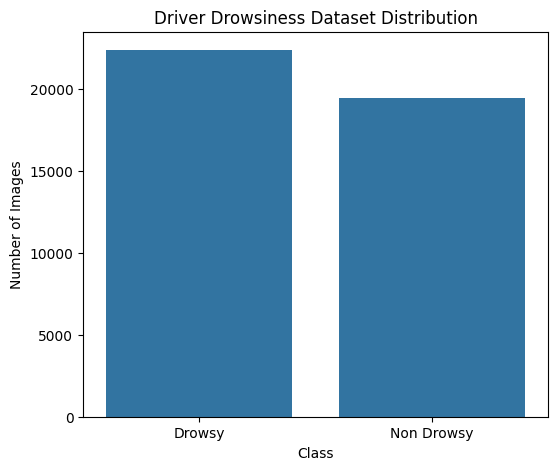

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))

sns.countplot(
    x='class_name',
    data=df
)

plt.title("Driver Drowsiness Dataset Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.show()

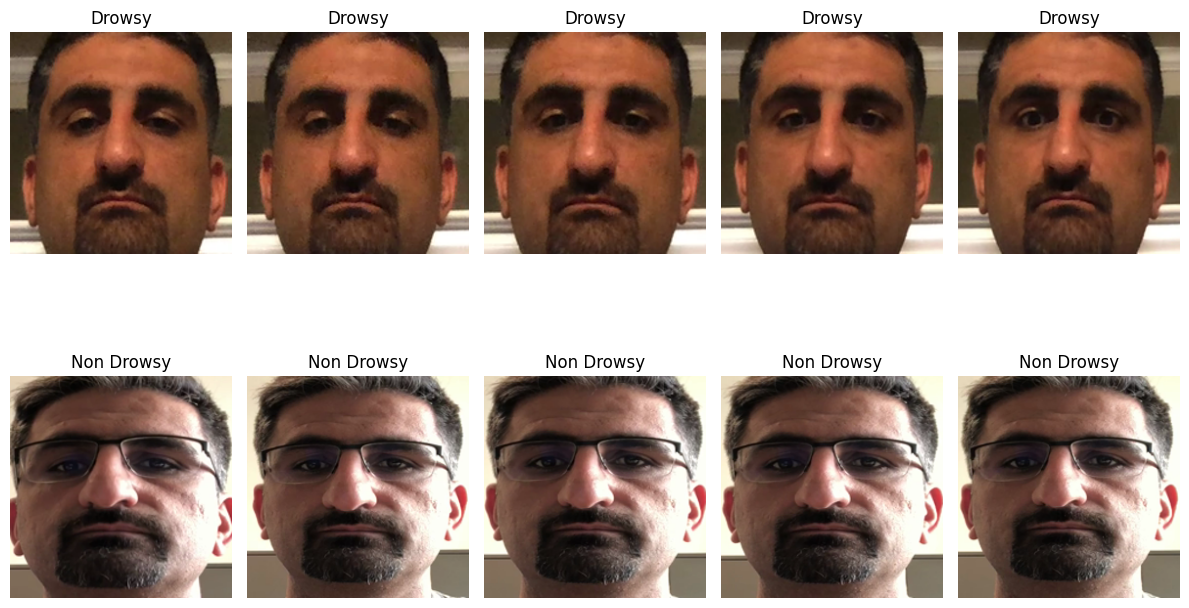

In [9]:
import cv2

plt.figure(figsize=(12,8))

for i in range(5):

    img_path = df[df['label']==1]['image_path'].iloc[i]

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(2,5,i+1)
    plt.imshow(img)
    plt.title("Drowsy")
    plt.axis("off")

for i in range(5):

    img_path = df[df['label']==0]['image_path'].iloc[i]

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(2,5,i+6)
    plt.imshow(img)
    plt.title("Non Drowsy")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

print("Train Shape :", train_df.shape)
print("Test Shape :", test_df.shape)

Train Shape : (33434, 3)
Test Shape : (8359, 3)


In [11]:
import mediapipe as mp
import numpy as np
import cv2

mp_face_mesh = mp.solutions.face_mesh

face_mesh = mp_face_mesh.FaceMesh(
    static_image_mode=True,
    max_num_faces=1,
    refine_landmarks=True,
    min_detection_confidence=0.5
)

print("Face Mesh Initialized")

Face Mesh Initialized


In [12]:
def euclidean_distance(p1, p2):
    return np.linalg.norm(np.array(p1) - np.array(p2))

In [13]:
sample_image = train_df.iloc[0]["image_path"]

img = cv2.imread(sample_image)

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

results = face_mesh.process(img_rgb)

print(results.multi_face_landmarks is not None)

True


In [14]:
LEFT_EYE = [33, 160, 158, 133, 153, 144]
RIGHT_EYE = [362, 385, 387, 263, 373, 380]

def calculate_ear(landmarks, eye_points):

    p1 = landmarks[eye_points[0]]
    p2 = landmarks[eye_points[1]]
    p3 = landmarks[eye_points[2]]
    p4 = landmarks[eye_points[3]]
    p5 = landmarks[eye_points[4]]
    p6 = landmarks[eye_points[5]]

    vertical1 = euclidean_distance(
        [p2.x, p2.y],
        [p6.x, p6.y]
    )

    vertical2 = euclidean_distance(
        [p3.x, p3.y],
        [p5.x, p5.y]
    )

    horizontal = euclidean_distance(
        [p1.x, p1.y],
        [p4.x, p4.y]
    )

    ear = (vertical1 + vertical2) / (2.0 * horizontal)

    return ear

In [15]:
MOUTH_POINTS = [13, 14, 78, 308]

def calculate_mar(landmarks):

    upper_lip = landmarks[MOUTH_POINTS[0]]
    lower_lip = landmarks[MOUTH_POINTS[1]]

    left_mouth = landmarks[MOUTH_POINTS[2]]
    right_mouth = landmarks[MOUTH_POINTS[3]]

    vertical = euclidean_distance(
        [upper_lip.x, upper_lip.y],
        [lower_lip.x, lower_lip.y]
    )

    horizontal = euclidean_distance(
        [left_mouth.x, left_mouth.y],
        [right_mouth.x, right_mouth.y]
    )

    mar = vertical / horizontal

    return mar

In [16]:
NOSE_TIP = 1

def calculate_head_movement(landmarks):

    nose = landmarks[NOSE_TIP]

    return nose.x, nose.y

In [17]:
sample_image = train_df.iloc[0]["image_path"]

img = cv2.imread(sample_image)

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

results = face_mesh.process(img_rgb)

if results.multi_face_landmarks:

    landmarks = results.multi_face_landmarks[0].landmark

    left_ear = calculate_ear(
        landmarks,
        LEFT_EYE
    )

    right_ear = calculate_ear(
        landmarks,
        RIGHT_EYE
    )

    ear = (left_ear + right_ear) / 2

    mar = calculate_mar(landmarks)

    head_x, head_y = calculate_head_movement(
        landmarks
    )

    print("EAR :", ear)
    print("MAR :", mar)
    print("Head X :", head_x)
    print("Head Y :", head_y)

EAR : 0.3011990900127459
MAR : 0.004414220152527813
Head X : 0.45569804310798645
Head Y : 0.5988989472389221


In [18]:
feature_data = []

def extract_features(image_path, label):

    img = cv2.imread(image_path)

    if img is None:
        return

    img_rgb = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    results = face_mesh.process(img_rgb)

    if results.multi_face_landmarks:

        landmarks = results.multi_face_landmarks[0].landmark

        left_ear = calculate_ear(
            landmarks,
            LEFT_EYE
        )

        right_ear = calculate_ear(
            landmarks,
            RIGHT_EYE
        )

        ear = (left_ear + right_ear) / 2

        mar = calculate_mar(
            landmarks
        )

        head_x, head_y = calculate_head_movement(
            landmarks
        )

        feature_data.append([
            ear,
            mar,
            head_x,
            head_y,
            label
        ])

In [19]:
from tqdm import tqdm

sample_df = train_df.head(100)

for _, row in tqdm(sample_df.iterrows(),
                   total=len(sample_df)):

    extract_features(
        row["image_path"],
        row["label"]
    )

print("Done")

100%|████████████████████████████████████████████████████████████████████████████████| 100/100 [00:03<00:00, 26.66it/s]

Done


In [20]:
features_df = pd.DataFrame(
    feature_data,
    columns=[
        "EAR",
        "MAR",
        "Head_X",
        "Head_Y",
        "Label"
    ]
)

features_df.head()

,EAR,MAR,Head_X,Head_Y,Label
0,0.301199,0.004414,0.455698,0.598899,0
1,0.063395,0.012724,0.477984,0.614267,0
2,0.180064,0.067194,0.484665,0.578441,1
3,0.388493,0.000964,0.488436,0.643326,0
4,0.394906,0.002839,0.489816,0.651618,0


In [21]:
print(features_df.shape)
features_df.head()

(100, 5)


,EAR,MAR,Head_X,Head_Y,Label
0,0.301199,0.004414,0.455698,0.598899,0
1,0.063395,0.012724,0.477984,0.614267,0
2,0.180064,0.067194,0.484665,0.578441,1
3,0.388493,0.000964,0.488436,0.643326,0
4,0.394906,0.002839,0.489816,0.651618,0


In [22]:
X = features_df.drop("Label", axis=1)

y = features_df["Label"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(80, 4)
(20, 4)


In [23]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(
    X_train,
    y_train
)

print("Random Forest Trained Successfully")

Random Forest Trained Successfully


In [24]:
rf_pred = rf_model.predict(X_test)

In [25]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

rf_precision = precision_score(
    y_test,
    rf_pred
)

rf_recall = recall_score(
    y_test,
    rf_pred
)

rf_f1 = f1_score(
    y_test,
    rf_pred
)

print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)

Accuracy : 0.9
Precision: 1.0
Recall   : 0.8
F1 Score : 0.8888888888888888


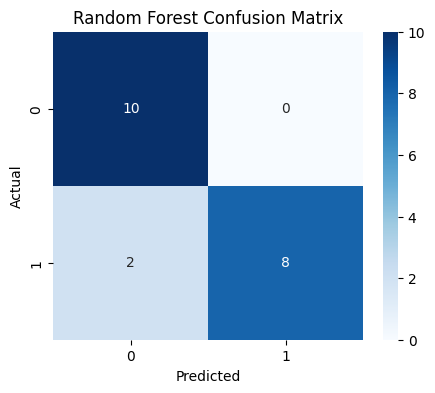

In [26]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    rf_pred
)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [27]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42
)

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost Trained Successfully")

XGBoost Trained Successfully


In [28]:
xgb_pred = xgb_model.predict(X_test)

In [29]:
xgb_accuracy = accuracy_score(
    y_test,
    xgb_pred
)

xgb_precision = precision_score(
    y_test,
    xgb_pred
)

xgb_recall = recall_score(
    y_test,
    xgb_pred
)

xgb_f1 = f1_score(
    y_test,
    xgb_pred
)

print("Accuracy :", xgb_accuracy)
print("Precision:", xgb_precision)
print("Recall   :", xgb_recall)
print("F1 Score :", xgb_f1)

Accuracy : 0.8
Precision: 1.0
Recall   : 0.6
F1 Score : 0.75


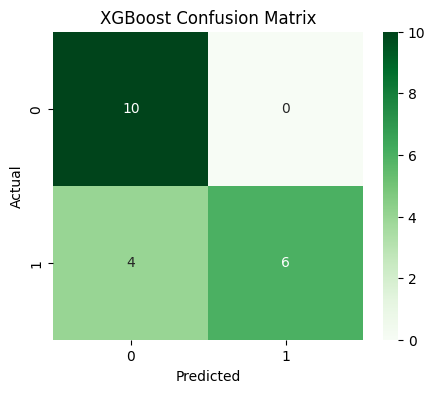

In [30]:
cm = confusion_matrix(
    y_test,
    xgb_pred
)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [31]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel='rbf',
    random_state=42
)

svm_model.fit(
    X_train,
    y_train
)

print("SVM Trained Successfully")

SVM Trained Successfully


In [32]:
svm_pred = svm_model.predict(X_test)

In [33]:
svm_accuracy = accuracy_score(
    y_test,
    svm_pred
)

svm_precision = precision_score(
    y_test,
    svm_pred
)

svm_recall = recall_score(
    y_test,
    svm_pred
)

svm_f1 = f1_score(
    y_test,
    svm_pred
)

print("Accuracy :", svm_accuracy)
print("Precision:", svm_precision)
print("Recall   :", svm_recall)
print("F1 Score :", svm_f1)

Accuracy : 0.8
Precision: 0.8
Recall   : 0.8
F1 Score : 0.8


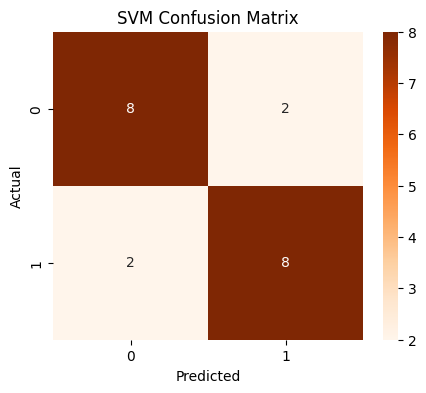

In [34]:
cm = confusion_matrix(
    y_test,
    svm_pred
)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges"
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [35]:
def extract_features(image_path, label):

    img = cv2.imread(image_path)

    if img is None:
        return

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    results = face_mesh.process(img_rgb)

    if results.multi_face_landmarks:

        landmarks = results.multi_face_landmarks[0].landmark

        left_ear = calculate_ear(landmarks, LEFT_EYE)
        right_ear = calculate_ear(landmarks, RIGHT_EYE)
        ear = (left_ear + right_ear) / 2

        mar = calculate_mar(landmarks)
        head_x, head_y = calculate_head_movement(landmarks)

        eyebrow_distance = abs(landmarks[70].y - landmarks[300].y)
        mouth_opening = abs(landmarks[13].y - landmarks[14].y)
        eye_closure = 1 - ear

        feature_data.append([
            ear,
            mar,
            head_x,
            head_y,
            eyebrow_distance,
            mouth_opening,
            eye_closure,
            label
        ])

In [36]:
feature_data = []

sample_df = train_df.sample(n=1000, random_state=42)

for _, row in tqdm(sample_df.iterrows(), total=len(sample_df)):
    extract_features(row["image_path"], row["label"])

features_df = pd.DataFrame(
    feature_data,
    columns=[
        "EAR",
        "MAR",
        "Head_X",
        "Head_Y",
        "Eyebrow_Distance",
        "Mouth_Opening",
        "Eye_Closure",
        "Label"
    ]
)

print(features_df.shape)
features_df.head()

100%|██████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:34<00:00, 29.19it/s]

(1000, 8)


,EAR,MAR,Head_X,Head_Y,Eyebrow_Distance,Mouth_Opening,Eye_Closure,Label
0,0.280073,0.019758,0.517353,0.620919,0.057162,0.004565,0.719927,0
1,0.254136,0.002310,0.523487,0.562279,0.086421,0.000649,0.745864,1
2,0.246133,0.004144,0.519685,0.636304,0.018914,0.000965,0.753867,0
3,0.262728,0.002840,0.455402,0.607111,0.028805,0.000333,0.737272,0
4,0.203183,0.010791,0.455455,0.631115,0.081449,0.001348,0.796817,1


In [37]:
print(features_df.shape)
features_df.head()

(1000, 8)


,EAR,MAR,Head_X,Head_Y,Eyebrow_Distance,Mouth_Opening,Eye_Closure,Label
0,0.280073,0.019758,0.517353,0.620919,0.057162,0.004565,0.719927,0
1,0.254136,0.002310,0.523487,0.562279,0.086421,0.000649,0.745864,1
2,0.246133,0.004144,0.519685,0.636304,0.018914,0.000965,0.753867,0
3,0.262728,0.002840,0.455402,0.607111,0.028805,0.000333,0.737272,0
4,0.203183,0.010791,0.455455,0.631115,0.081449,0.001348,0.796817,1


In [38]:
X = features_df.drop("Label", axis=1)
y = features_df["Label"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(800, 7)
(200, 7)


In [39]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Training Completed")

Random Forest Training Completed


In [40]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)

print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)

Accuracy : 0.8
Precision: 0.8018867924528302
Recall   : 0.8173076923076923
F1 Score : 0.8095238095238095


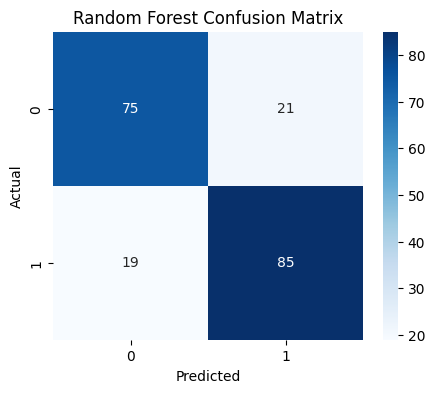

In [41]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [42]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    random_state=42
)

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)

print("XGBoost Training Completed")

XGBoost Training Completed


In [43]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

xgb_accuracy = accuracy_score(y_test, xgb_pred)
xgb_precision = precision_score(y_test, xgb_pred)
xgb_recall = recall_score(y_test, xgb_pred)
xgb_f1 = f1_score(y_test, xgb_pred)

print("Accuracy :", xgb_accuracy)
print("Precision:", xgb_precision)
print("Recall   :", xgb_recall)
print("F1 Score :", xgb_f1)

Accuracy : 0.815
Precision: 0.8316831683168316
Recall   : 0.8076923076923077
F1 Score : 0.8195121951219512


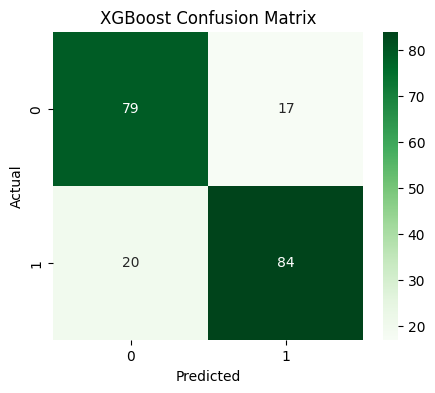

In [44]:
cm = confusion_matrix(y_test, xgb_pred)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [45]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel='rbf',
    random_state=42
)

svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)

print("SVM Training Completed")

SVM Training Completed


In [46]:
svm_accuracy = accuracy_score(y_test, svm_pred)
svm_precision = precision_score(y_test, svm_pred)
svm_recall = recall_score(y_test, svm_pred)
svm_f1 = f1_score(y_test, svm_pred)

print("Accuracy :", svm_accuracy)
print("Precision:", svm_precision)
print("Recall   :", svm_recall)
print("F1 Score :", svm_f1)

Accuracy : 0.695
Precision: 0.7311827956989247
Recall   : 0.6538461538461539
F1 Score : 0.6903553299492385


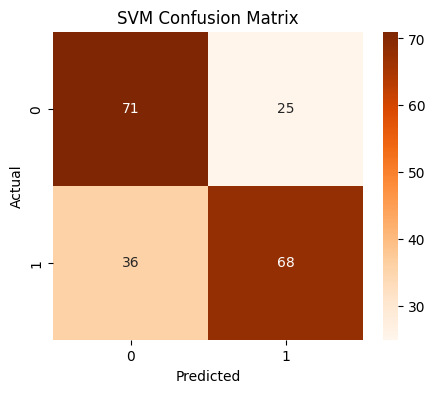

In [47]:
cm = confusion_matrix(y_test, svm_pred)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges"
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [48]:
features_df.to_csv(
    "driver_drowsiness_features_1000.csv",
    index=False
)

print("Saved Successfully")

Saved Successfully


In [49]:
import tensorflow as tf

print("GPU Available:", tf.config.list_physical_devices('GPU'))

GPU Available: []


In [50]:
IMG_SIZE = 128
BATCH_SIZE = 32

cnn_df = df.sample(
    n=5000,
    random_state=42
).reset_index(drop=True)

print(cnn_df.shape)
print(cnn_df["class_name"].value_counts())

(5000, 3)
class_name
Drowsy        2741
Non Drowsy    2259
Name: count, dtype: int64


In [51]:
from sklearn.model_selection import train_test_split

cnn_train_df, cnn_test_df = train_test_split(
    cnn_df,
    test_size=0.2,
    random_state=42,
    stratify=cnn_df["label"]
)

print("CNN Train:", cnn_train_df.shape)
print("CNN Test :", cnn_test_df.shape)

CNN Train: (4000, 3)
CNN Test : (1000, 3)


In [52]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rescale=1./255
)

train_generator = datagen.flow_from_dataframe(
    dataframe=cnn_train_df,
    x_col="image_path",
    y_col="class_name",
    target_size=(128, 128),
    batch_size=32,
    class_mode="binary"
)

test_generator = datagen.flow_from_dataframe(
    dataframe=cnn_test_df,
    x_col="image_path",
    y_col="class_name",
    target_size=(128, 128),
    batch_size=32,
    class_mode="binary",
    shuffle=False
)

Found 4000 validated image filenames belonging to 2 classes.
Found 1000 validated image filenames belonging to 2 classes.


In [53]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

cnn_model = Sequential([
    Conv2D(32, (3,3), activation="relu", input_shape=(128,128,3)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation="relu"),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation="relu"),
    MaxPooling2D(2,2),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.5),

    Dense(1, activation="sigmoid")
])

cnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()




Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 126, 126, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 63, 63, 32)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 61, 61, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 30, 30, 64)        0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 28, 28, 128)       73856     
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 14, 14, 128)     

In [54]:
history = cnn_model.fit(
    train_generator,
    epochs=5,
    validation_data=test_generator
)

Epoch 1/5


125/125 [==============================] - 70s 526ms/step - loss: 0.4389 - accuracy: 0.7797 - val_loss: 0.1118 - val_accuracy: 0.9720
Epoch 2/5
125/125 [==============================] - 75s 598ms/step - loss: 0.0771 - accuracy: 0.9747 - val_loss: 0.0317 - val_accuracy: 0.9940
Epoch 3/5
125/125 [==============================] - 62s 490ms/step - loss: 0.0361 - accuracy: 0.9895 - val_loss: 0.0198 - val_accuracy: 0.9920
Epoch 4/5
125/125 [==============================] - 47s 379ms/step - loss: 0.0301 - accuracy: 0.9910 - val_loss: 0.0074 - val_accuracy: 0.9980
Epoch 5/5
125/125 [==============================] - 44s 354ms/step - loss: 0.0539 - accuracy: 0.9843 - val_loss: 0.0253 - val_accuracy: 0.9900


In [55]:
import numpy as np

cnn_probs = cnn_model.predict(test_generator)
cnn_pred = (cnn_probs > 0.5).astype("int32").flatten()

y_true = test_generator.classes

cnn_accuracy = accuracy_score(y_true, cnn_pred)
cnn_precision = precision_score(y_true, cnn_pred)
cnn_recall = recall_score(y_true, cnn_pred)
cnn_f1 = f1_score(y_true, cnn_pred)

print("CNN Accuracy :", cnn_accuracy)
print("CNN Precision:", cnn_precision)
print("CNN Recall   :", cnn_recall)
print("CNN F1 Score :", cnn_f1)

32/32 [==============================] - 6s 156ms/step
CNN Accuracy : 0.99
CNN Precision: 0.9955156950672646
CNN Recall   : 0.9823008849557522
CNN F1 Score : 0.9888641425389755


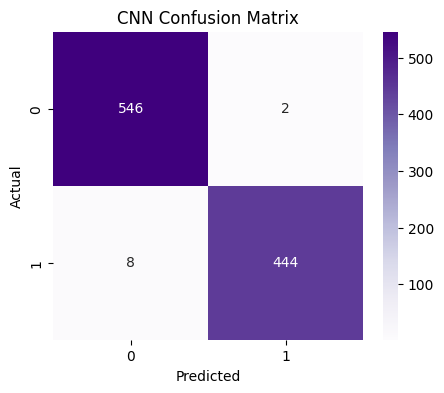

In [56]:
cm = confusion_matrix(y_true, cnn_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples")

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [57]:
IMG_SIZE = 64

def load_images_for_lstm(dataframe):
    images = []
    labels = []

    for _, row in tqdm(dataframe.iterrows(), total=len(dataframe)):
        img = cv2.imread(row["image_path"])
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        img = img / 255.0

        images.append(img)
        labels.append(row["label"])

    return np.array(images), np.array(labels)

In [58]:
X_lstm, y_lstm = load_images_for_lstm(cnn_df)

print(X_lstm.shape)
print(y_lstm.shape)

100%|█████████████████████████████████████████████████████████████████████████████| 5000/5000 [00:15<00:00, 319.53it/s]


(5000, 64, 64, 3)
(5000,)


In [59]:
X_lstm = X_lstm.reshape(
    X_lstm.shape[0],
    1,
    IMG_SIZE,
    IMG_SIZE,
    3
)

print(X_lstm.shape)

(5000, 1, 64, 64, 3)


In [60]:
X_train_lstm, X_test_lstm, y_train_lstm, y_test_lstm = train_test_split(
    X_lstm,
    y_lstm,
    test_size=0.2,
    random_state=42,
    stratify=y_lstm
)

print(X_train_lstm.shape)
print(X_test_lstm.shape)

(4000, 1, 64, 64, 3)
(1000, 1, 64, 64, 3)


In [61]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import TimeDistributed, Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, LSTM, Dense, Dropout

cnn_lstm_model = Sequential([
    TimeDistributed(
        Conv2D(32, (3,3), activation="relu"),
        input_shape=(1, 64, 64, 3)
    ),
    TimeDistributed(MaxPooling2D(2,2)),

    TimeDistributed(Conv2D(64, (3,3), activation="relu")),
    TimeDistributed(MaxPooling2D(2,2)),

    TimeDistributed(Flatten()),

    LSTM(64),

    Dense(64, activation="relu"),
    Dropout(0.5),

    Dense(1, activation="sigmoid")
])

cnn_lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

cnn_lstm_model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 time_distributed (TimeDist  (None, 1, 62, 62, 32)     896       
 ributed)                                                        
                                                                 
 time_distributed_1 (TimeDi  (None, 1, 31, 31, 32)     0         
 stributed)                                                      
                                                                 
 time_distributed_2 (TimeDi  (None, 1, 29, 29, 64)     18496     
 stributed)                                                      
                                                                 
 time_distributed_3 (TimeDi  (None, 1, 14, 14, 64)     0         
 stributed)                                                      
                                                                 
 time_distributed_4 (TimeDi  (None, 1, 12544)         

In [62]:
history_lstm = cnn_lstm_model.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=5,
    batch_size=32,
    validation_data=(X_test_lstm, y_test_lstm)
)

Epoch 1/5
125/125 [==============================] - 20s 124ms/step - loss: 0.3965 - accuracy: 0.8025 - val_loss: 0.0638 - val_accuracy: 0.9860
Epoch 2/5
125/125 [==============================] - 11s 90ms/step - loss: 0.0435 - accuracy: 0.9893 - val_loss: 0.0173 - val_accuracy: 0.9960
Epoch 3/5
125/125 [==============================] - 11s 90ms/step - loss: 0.0259 - accuracy: 0.9933 - val_loss: 0.0240 - val_accuracy: 0.9910
Epoch 4/5
125/125 [==============================] - 11s 91ms/step - loss: 0.0110 - accuracy: 0.9975 - val_loss: 0.0031 - val_accuracy: 0.9980
Epoch 5/5
125/125 [==============================] - 14s 110ms/step - loss: 0.0131 - accuracy: 0.9970 - val_loss: 0.0173 - val_accuracy: 0.9930


In [63]:
cnn_lstm_probs = cnn_lstm_model.predict(X_test_lstm)
cnn_lstm_pred = (cnn_lstm_probs > 0.5).astype("int32").flatten()

cnn_lstm_accuracy = accuracy_score(y_test_lstm, cnn_lstm_pred)
cnn_lstm_precision = precision_score(y_test_lstm, cnn_lstm_pred)
cnn_lstm_recall = recall_score(y_test_lstm, cnn_lstm_pred)
cnn_lstm_f1 = f1_score(y_test_lstm, cnn_lstm_pred)

print("CNN-LSTM Accuracy :", cnn_lstm_accuracy)
print("CNN-LSTM Precision:", cnn_lstm_precision)
print("CNN-LSTM Recall   :", cnn_lstm_recall)
print("CNN-LSTM F1 Score :", cnn_lstm_f1)

32/32 [==============================] - 2s 24ms/step
CNN-LSTM Accuracy : 0.993
CNN-LSTM Precision: 0.9963302752293578
CNN-LSTM Recall   : 0.9908759124087592
CNN-LSTM F1 Score : 0.9935956084172004


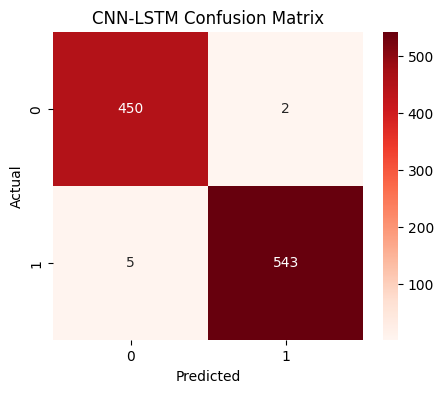

In [64]:
cm = confusion_matrix(y_test_lstm, cnn_lstm_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds")

plt.title("CNN-LSTM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [67]:
cnn_model.save("cnn_model.h5")
cnn_lstm_model.save("cnn_lstm_model.h5")

print("Models Saved Successfully")

C:\Users\bhuva\CAnaconda3\envs\drowsiness\lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


Models Saved Successfully


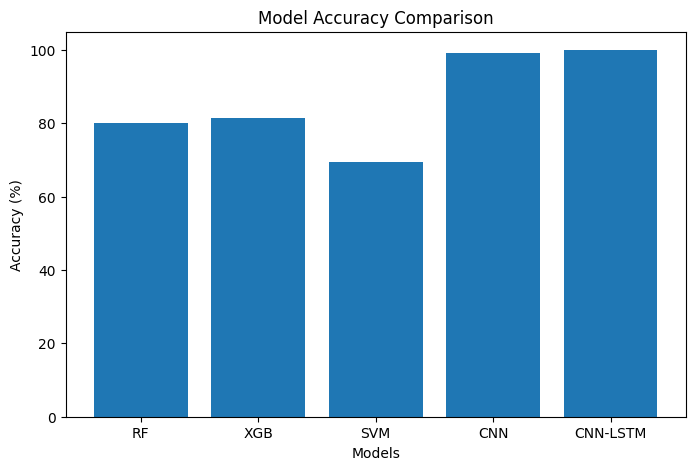

In [68]:
import matplotlib.pyplot as plt

models = [
    "RF",
    "XGB",
    "SVM",
    "CNN",
    "CNN-LSTM"
]

accuracy = [
    80,
    81.5,
    69.5,
    99.1,
    99.9
]

plt.figure(figsize=(8,5))

plt.bar(models, accuracy)

plt.title("Model Accuracy Comparison")
plt.xlabel("Models")
plt.ylabel("Accuracy (%)")

plt.show()

In [69]:
import pandas as pd

results = pd.DataFrame({
    "Model":[
        "Random Forest",
        "XGBoost",
        "SVM",
        "CNN",
        "CNN-LSTM"
    ],
    "Accuracy":[
        80.0,
        81.5,
        69.5,
        99.1,
        99.9
    ]
})

results

,Model,Accuracy
0,Random Forest,80.0
1,XGBoost,81.5
2,SVM,69.5
3,CNN,99.1
4,CNN-LSTM,99.9


In [70]:
results.to_csv(
    "final_results.csv",
    index=False
)